# Modelo Vectorial de Corrección del Error (VECM) aplicado
## ¿Cómo se traslada el precio mayorista de la gasolina al precio en surtidor?

| Campo | Detalle |
|---|---|
| **Área** | Series de tiempo multivariadas · Cointegración · Econometría de la energía |
| **Nivel** | Maestría en Analítica de Datos |
| **Herramientas** | Python 3, `pandas`, `numpy`, `statsmodels`, `scipy`, `matplotlib`, `seaborn` |
| **Datos** | Precio minorista promedio de la gasolina regular en EE. UU. (EIA, `GASREGW`) y precio mayorista *spot* de gasolina convencional en el puerto de Nueva York (EIA, `DGASNYH`), vía FRED |
| **Frecuencia y período** | Semanal (lunes), enero 2010 – diciembre 2019 para el caso base; el archivo llega hasta octubre de 2026 para ejercicios |
| **Archivo de datos** | `datos_gasolina_vec.csv` (congelado; el cuaderno no necesita internet) |

### Por qué este caso funciona bien para aprender VECM

1. **La teoría económica dicta la relación de equilibrio.** El precio en surtidor = costo mayorista + impuestos por galón +
   margen de distribución y venta. Se espera una relación casi uno a uno y una constante interpretable en dólares.
2. **La estadística acompaña.** Ambas series son claramente $I(1)$, la prueba de Johansen encuentra exactamente una relación
   de cointegración en todas las especificaciones razonables y los coeficientes de ajuste tienen una lectura nítida:
   **el minorista corrige, el mayorista no**.
3. **Hay una pregunta famosa detrás:** ¿suben los precios "como cohetes" y bajan "como plumas"? (Bacon, 1991;
   Borenstein, Cameron y Gilbert, 1997). El VECM es la base para responderla.

### Mapa del cuaderno

| Módulo | Tema |
|---|---|
| 0 | Configuración |
| 1 | Problema económico y preguntas |
| 2 | Datos: fuente, construcción semanal y exploración |
| 3 | Orden de integración (ADF y KPSS) |
| 4 | Selección de rezagos |
| 5 | Prueba de Johansen con constante restringida |
| 6 | Estimación e interpretación del VECM ($\beta$, $\alpha$, $\Gamma$) |
| 7 | Diagnóstico y robustez |
| 8 | Funciones impulso-respuesta y traspaso (*pass-through*) |
| 9 | Extensión: asimetría "cohetes y plumas" |
| 10 | Pronóstico con validación temporal |
| 11 | Conclusiones y limitaciones |
| 12 | Actividades |

> Este cuaderno es complementario a `15_Cointegracion_VECM_Mejorado.ipynb` (crudo y gasóleo), donde se desarrolla con
> más detalle la teoría VAR → VECM con datos simulados. Aquí se repasa lo esencial y se pone el foco en la aplicación.

---
## Módulo 0. Configuración

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, coint_johansen
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import display

warnings.filterwarnings("ignore", category=InterpolationWarning)        # p-valor de KPSS fuera de tabla (se indica en la tabla)
warnings.filterwarnings("ignore", message=".*frequency information.*")
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)  # autovalores reales guardados como complejos

SEMILLA = 2024
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4.2), "figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "legend.frameon": False, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.7})
COL = {"minorista": "#2a78d6", "mayorista": "#eb6834", "ECT": "#6250d6", "VECM": "#2a78d6",
       "VAR_dif": "#eb6834", "VAR_niv": "#1baf7a", "Ingenuo": "#7a7974", "obs": "#222222", "ref": "#9a9994"}
ETQ = {"minorista": "Minorista (surtidor, EE. UU.)", "mayorista": "Mayorista (spot NY Harbor)"}

def eje_fechas(ax, paso=1):
    ax.xaxis.set_major_locator(mdates.YearLocator(paso))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for lib in (np, pd, scipy, statsmodels, matplotlib, sns):
    print(f"{lib.__name__:<12} {lib.__version__}")

numpy        2.4.4
pandas       2.3.3
scipy        1.15.3
statsmodels  0.14.6
matplotlib   3.10.0
seaborn      0.13.2


---
## Módulo 1. Problema económico

**Objetivo de aprendizaje:** traducir una pregunta de mercado en una hipótesis de cointegración con signos esperados.

### 1.1 ¿De qué está hecho el precio en surtidor?

Para un galón de gasolina regular en EE. UU., el precio que paga el consumidor se descompone, aproximadamente, en:

| Componente | Naturaleza | Cómo se mueve |
|---|---|---|
| Petróleo crudo y refinación | Recogido por el **precio mayorista** (*spot*) | Cambia todos los días |
| Impuestos | Federal fijo de 18.4 centavos por galón más impuestos estatales (en su mayoría también por galón) | Casi constante semana a semana |
| Distribución y margen minorista | Transporte, terminales, margen de la estación de servicio | Varía, pero alrededor de un nivel típico |

Si los impuestos y el margen típico fueran constantes, tendríamos

$$P^{min}_t \approx \mu + b\,P^{may}_t, \qquad b\approx 1,\quad \mu > 0 \text{ (USD por galón)}.$$

La diferencia $P^{min}_t - \mu - bP^{may}_t$ es el **margen anormal**: cuando es positiva, las estaciones están cobrando
más de lo habitual sobre su costo; cuando es negativa, su margen está comprimido.

### 1.2 ¿Por qué niveles y no logaritmos?

Los impuestos y buena parte de los costos de distribución son **centavos por galón**, no porcentajes. La relación natural es
aditiva, en USD/galón, y la constante se lee directamente en dinero. (Con logaritmos el análisis también es posible; se
propone como ejercicio.)

### 1.3 Hipótesis y preguntas

- **H1 (largo plazo):** minorista y mayorista están cointegrados con $b$ cercano a 1 y $\mu$ positivo.
- **H2 (ajuste):** el precio **minorista** corrige los desequilibrios; el mayorista, que se forma en un mercado nacional e
  internacional mucho más amplio, no reacciona a los márgenes de las estaciones (**exogeneidad débil**).
- **H3 (dinámica):** el traslado de un cambio mayorista al surtidor no es inmediato, sino que tarda algunas semanas.
- **H4 (asimetría):** las subidas del mayorista se trasladan más rápido que las bajadas.

### 1.4 El VECM que vamos a estimar

Con $\mathbf y_t = (P^{min}_t,\ P^{may}_t)'$ y una relación de cointegración ($r=1$):

$$\Delta\mathbf y_t = \boldsymbol\alpha\big(\boldsymbol\beta'\mathbf y_{t-1} + \mu_0\big)
+ \sum_{i=1}^{p-1}\boldsymbol\Gamma_i\Delta\mathbf y_{t-i} + \boldsymbol\varepsilon_t,$$

donde $\boldsymbol\beta'\mathbf y_{t-1} + \mu_0 = P^{min}_{t-1} + \beta_2 P^{may}_{t-1} + \mu_0$ es el margen anormal de la semana
anterior (ECT). Con esta normalización, **H2 se traduce en $\alpha_{min}<0$ y $\alpha_{may}=0$**: si el margen está por encima de
lo normal ($ECT>0$), el precio minorista baja.

La constante va **dentro** de la relación de cointegración (`deterministic="ci"`), porque los precios de la gasolina no tienen
una deriva sistemática y la constante es, precisamente, el margen típico más impuestos.

---
## Módulo 2. Datos

**Objetivo de aprendizaje:** documentar la procedencia de los datos y la construcción de una base semanal coherente.

### 2.1 Fuente

| Variable | Serie FRED | Fuente original | Unidad | Frecuencia original |
|---|---|---|---|---|
| Precio minorista | `GASREGW` — *US Regular All Formulations Gas Price* | U.S. Energy Information Administration (EIA) | USD/galón, con impuestos | Semanal (lunes) |
| Precio mayorista | `DGASNYH` — *Conventional Gasoline Prices: New York Harbor, Regular* | EIA | USD/galón, sin impuestos | Diaria (días hábiles) |

Descargadas de FRED (Federal Reserve Bank of St. Louis) el 31 de octubre de 2026.

### 2.2 Construcción de la base semanal (ya hecha en el archivo)

El precio minorista de la EIA se recoge cada **lunes**. Para alinear el mayorista se calculó el **promedio de los precios
diarios de la semana que termina ese lunes** (martes a lunes). Así, cada fila compara el precio en surtidor del lunes con el
costo mayorista de los días previos, que es la información disponible para las estaciones. La columna
`dias_con_dato_mayorista` indica cuántos días hábiles entraron en el promedio.

La función `reconstruir_desde_fred` permite repetir la construcción con datos actualizados (requiere internet y es opcional).

In [2]:
RUTA = Path("datos_gasolina_vec.csv")
if not RUTA.exists():
    raise FileNotFoundError("No se encuentra 'datos_gasolina_vec.csv' en la carpeta del cuaderno.")

def reconstruir_desde_fred():
    # Opcional: descarga las series de FRED y repite la construcción semanal (requiere internet)
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
    leer = lambda s: pd.read_csv(url.format(s), parse_dates=[0], index_col=0, na_values=".").iloc[:, 0]
    diario = leer("DGASNYH")
    sem = diario.resample("W-MON").agg(["mean", "count"])     # semana (martes, lunes], etiquetada con el lunes
    return pd.concat([leer("GASREGW").rename("minorista_usd_galon"),
                      sem["mean"].rename("mayorista_nyh_usd_galon"),
                      sem["count"].rename("dias_con_dato_mayorista")], axis=1).dropna(subset=["minorista_usd_galon"])

base = pd.read_csv(RUTA, parse_dates=["fecha_lunes"], index_col="fecha_lunes").sort_index()
print(f"Semanas en el archivo: {len(base)}  ({base.index[0].date()} → {base.index[-1].date()})")
print("¿Todas las fechas son lunes?", bool((base.index.dayofweek == 0).all()))
print("Faltantes:", base.isna().sum().to_dict())
print("Distribución de días con dato mayorista por semana:", base["dias_con_dato_mayorista"].value_counts().sort_index().to_dict())

Semanas en el archivo: 1400  (2000-01-03 → 2026-10-26)
¿Todas las fechas son lunes? True
Faltantes: {'minorista_usd_galon': 0, 'mayorista_nyh_usd_galon': 1, 'dias_con_dato_mayorista': 0}
Distribución de días con dato mayorista por semana: {0: 1, 1: 10, 2: 27, 3: 92, 4: 310, 5: 960}


In [3]:
INICIO, FIN = "2010-01-01", "2019-12-31"
y = (base.loc[INICIO:FIN, ["minorista_usd_galon", "mayorista_nyh_usd_galon"]]
         .rename(columns={"minorista_usd_galon": "minorista", "mayorista_nyh_usd_galon": "mayorista"}))
y.index.freq = "W-MON"
assert y.isna().sum().sum() == 0 and (y > 0).all().all()
dif = y.diff().dropna()
margen = y["minorista"] - y["mayorista"]

print(f"Muestra del caso base: T = {len(y)} semanas ({y.index[0].date()} → {y.index[-1].date()})")
print("Semanas con menos de 3 días de dato mayorista:", int((base.loc[INICIO:FIN, 'dias_con_dato_mayorista'] < 3).sum()))
display(pd.concat([y.describe().T, margen.describe().to_frame("minorista − mayorista").T]).round(3))

Muestra del caso base: T = 522 semanas (2010-01-04 → 2019-12-30)
Semanas con menos de 3 días de dato mayorista: 1


,count,mean,std,min,25%,50%,75%,max
minorista,522.0,2.910,0.555,1.724,2.450,2.806,3.451,3.965
mayorista,522.0,2.156,0.589,0.994,1.656,2.045,2.728,3.401
minorista − mayorista,522.0,0.754,0.106,0.403,0.684,0.752,0.830,1.081


### 2.3 ¿Por qué 2010-2019?

- Es un período **sin cambios de régimen extremos**: excluye la crisis de 2008, el colapso de demanda de 2020 y la
  crisis de refinación de 2022. Incluye, eso sí, la caída del petróleo de 2014-2016, que da variación útil.
- 522 semanas dan potencia suficiente a las pruebas.
- El período 2020-2026 queda para el ejercicio integrador: ¿sobrevive la relación a la pandemia y a 2022?

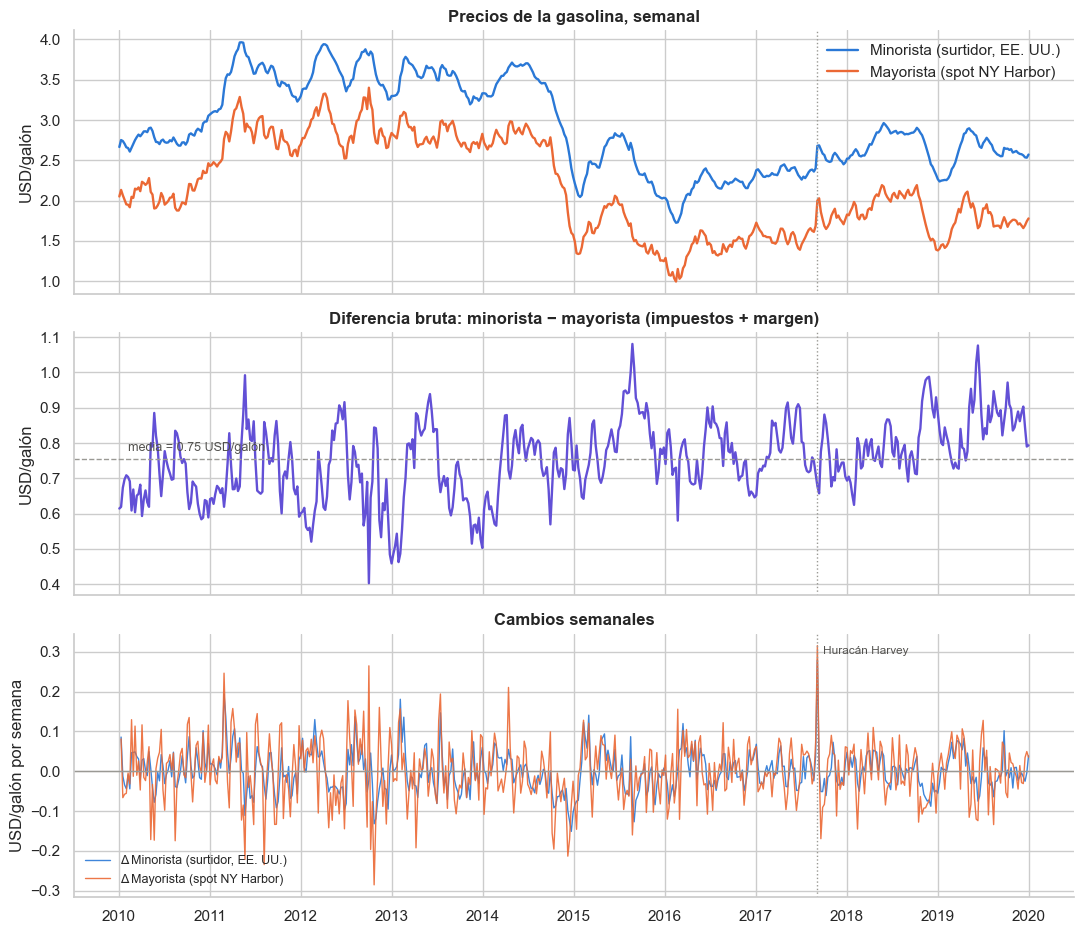

Correlación de los cambios semanales (mismo lunes): 0.671
Correlación del cambio minorista con el cambio mayorista de la semana anterior: 0.58
Mayores cambios semanales del mayorista:


,|Δ mayorista|
fecha_lunes,
2017-09-04,0.316
2012-10-22,0.285
2012-10-01,0.265
2011-02-28,0.247


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
for c in y:
    axes[0].plot(y.index, y[c], color=COL[c], label=ETQ[c])
axes[0].set_ylabel("USD/galón"); axes[0].set_title("Precios de la gasolina, semanal")
axes[0].legend(loc="upper right")

axes[1].plot(margen.index, margen, color=COL["ECT"])
axes[1].axhline(margen.mean(), color=COL["ref"], ls="--", lw=1)
axes[1].annotate(f"media = {margen.mean():.2f} USD/galón", (margen.index[5], margen.mean()), xytext=(0, 6),
                 textcoords="offset points", fontsize=9, color="#52514e")
axes[1].set_ylabel("USD/galón"); axes[1].set_title("Diferencia bruta: minorista − mayorista (impuestos + margen)")

for c in y:
    axes[2].plot(dif.index, dif[c], color=COL[c], lw=1, alpha=0.9, label="Δ " + ETQ[c])
axes[2].axhline(0, color=COL["ref"], lw=1)
axes[2].set_ylabel("USD/galón por semana"); axes[2].set_title("Cambios semanales")
axes[2].legend(loc="lower left", fontsize=9)
f_harvey = pd.Timestamp("2017-09-04")
for ax in axes:
    ax.axvline(f_harvey, color=COL["ref"], ls=":", lw=1)
axes[2].annotate("Huracán Harvey", (f_harvey, axes[2].get_ylim()[1] * 0.85), xytext=(4, 0),
                 textcoords="offset points", fontsize=8.5, color="#52514e")
eje_fechas(axes[2])
plt.tight_layout(); plt.show()

print("Correlación de los cambios semanales (mismo lunes):", round(dif.corr().iloc[0, 1], 3))
print("Correlación del cambio minorista con el cambio mayorista de la semana anterior:",
      round(dif["minorista"].corr(dif["mayorista"].shift(1)), 3))
print("Mayores cambios semanales del mayorista:")
display(dif["mayorista"].abs().nlargest(4).round(3).to_frame("|Δ mayorista|"))

**Lectura de los gráficos.**

- Las dos series se mueven juntas y no vuelven a un nivel fijo: caen con fuerza en 2014-2016 y se recuperan después.
- El minorista es **más suave**: su trayectoria parece un promedio retrasado del mayorista. El mayorista tiene saltos bruscos,
  como el del huracán Harvey (finales de agosto de 2017), que cerró refinerías del Golfo de México.
- La **diferencia bruta** (minorista − mayorista) no tiene tendencia y oscila alrededor de ≈ 0.75 USD/galón. Se amplía cuando
  el mayorista cae rápido (2015: el minorista tarda en bajar) y se comprime cuando el mayorista sube de golpe (otoño de 2012,
  con interrupciones en refinerías).
  Esa es, a simple vista, la huella de un mecanismo de corrección del error… y de una posible asimetría.
- En los cambios semanales, el cambio minorista está correlacionado con el cambio mayorista de la misma semana (≈ 0.67) y
  casi igual de fuerte con el de **la semana anterior** (≈ 0.58): parte del traslado ocurre en la semana y otra parte, después.

> **Comprueba tu comprensión.** Si los impuestos estatales subieran 10 centavos de forma permanente en todo el país, ¿qué
> parámetro del modelo cambiaría? ¿Seguiría habiendo cointegración?

---
## Módulo 3. Orden de integración

**Objetivo de aprendizaje:** verificar que ambas series son $I(1)$ combinando ADF ($H_0$: raíz unitaria) y KPSS
($H_0$: estacionariedad).

Especificación principal: **solo constante**, porque los precios no muestran tendencia determinista en 2010-2019.
Se reporta también la versión con tendencia como sensibilidad.

In [5]:
def tabla_raiz_unitaria(df, sufijo="", regs=("c", "ct"), alfa=0.05):
    filas = []
    for col in df.columns:
        for reg in regs:
            a = adfuller(df[col].dropna(), regression=reg, autolag="AIC")
            kst, kp, _, kcv = kpss(df[col].dropna(), regression=reg, nlags="auto")
            ra, rk = a[1] < alfa, kp < alfa
            filas.append({"Serie": sufijo + col, "Determinista": {"c": "constante", "ct": "const.+tend."}[reg],
                          "ADF estad.": a[0], "ADF p": a[1],
                          "KPSS estad.": kst, "KPSS p": "< 0.01" if kp <= 0.01 else ("> 0.10" if kp >= 0.10 else f"{kp:.3f}"),
                          "Lectura": {(False, True): "Raíz unitaria (coherente)", (True, False): "Estacionaria (coherente)",
                                      (False, False): "No concluyente", (True, True): "Contradictorio"}[(ra, rk)]})
    return pd.DataFrame(filas)

display(pd.concat([tabla_raiz_unitaria(y), tabla_raiz_unitaria(dif, "Δ", ("c",))], ignore_index=True).round(4))

,Serie,Determinista,ADF estad.,ADF p,KPSS estad.,KPSS p,Lectura
0,minorista,constante,-1.8653,0.3486,1.6007,< 0.01,Raíz unitaria (coherente)
1,minorista,const.+tend.,-2.4816,0.3372,0.3157,< 0.01,Raíz unitaria (coherente)
2,mayorista,constante,-1.6066,0.4803,1.7851,< 0.01,Raíz unitaria (coherente)
3,mayorista,const.+tend.,-2.4270,0.3654,0.3210,< 0.01,Raíz unitaria (coherente)
4,Δminorista,constante,-12.2348,0.0000,0.0913,> 0.10,Estacionaria (coherente)
5,Δmayorista,constante,-7.5546,0.0000,0.0915,> 0.10,Estacionaria (coherente)


**Interpretación.** En niveles, con constante, ADF no rechaza la raíz unitaria y KPSS rechaza la estacionariedad: evidencia
coherente de no estacionariedad. Con tendencia el resultado es igual. En primeras diferencias ambas pruebas apuntan a
estacionariedad. **Ambas series se comportan como $I(1)$**, con evidencia más nítida que en muchos ejemplos de manual.

> **Error frecuente.** Concluir "la serie es estacionaria" porque KPSS no rechaza, sin mirar el ADF. Las dos pruebas se leen juntas.

---
## Módulo 4. Selección de rezagos

**Objetivo de aprendizaje:** combinar criterios de información con el diagnóstico de residuos para fijar `k_ar_diff`.

`select_order` devuelve directamente el número de rezagos **en diferencias** del VECM (`k_ar_diff`); un VECM con
`k_ar_diff` $=p-1$ equivale a un VAR($p$) en niveles. Regla de decisión: entre los valores sugeridos por los criterios,
elegir el más pequeño cuyos residuos **no** muestren autocorrelación (prueba Portmanteau multivariada).

In [6]:
sel = select_order(y, maxlags=12, deterministic="ci")
print(sel.summary())
print({"AIC": sel.aic, "BIC": sel.bic, "HQIC": sel.hqic, "FPE": sel.fpe})

filas = []
for kd in range(1, 7):
    r_ = VECM(y, k_ar_diff=kd, coint_rank=1, deterministic="ci").fit()
    w = r_.test_whiteness(nlags=12, adjusted=True)
    filas.append({"k_ar_diff": kd, "criterio que lo elige": ", ".join(n for n, v in
                  {"AIC": sel.aic, "BIC": sel.bic, "HQIC": sel.hqic}.items() if v == kd) or "—",
                  "Portmanteau (12) estad.": w.test_statistic, "p-valor": w.pvalue})
tabla_rez = pd.DataFrame(filas).set_index("k_ar_diff")
display(tabla_rez.round(4))

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -12.00      -11.93   6.150e-06      -11.97
1       -12.46     -12.36*   3.861e-06      -12.43
2       -12.49      -12.36   3.746e-06     -12.44*
3      -12.50*      -12.33  3.738e-06*      -12.43
4       -12.49      -12.29   3.749e-06      -12.42
5       -12.48      -12.25   3.805e-06      -12.39
6       -12.47      -12.20   3.857e-06      -12.36
7       -12.45      -12.15   3.905e-06      -12.34
8       -12.45      -12.11   3.936e-06      -12.32
9       -12.47      -12.10   3.856e-06      -12.32
10      -12.46      -12.06   3.869e-06      -12.31
11      -12.46      -12.03   3.863e-06      -12.29
12      -12.46      -11.99   3.889e-06      -12.27
--------------------------------------------------
{'AIC': np.int64(3), 'BIC': np.int64(1), 'HQIC': np.int64(2), 'FPE': np.int64(3)}


,criterio que lo elige,Portmanteau (12) estad.,p-valor
k_ar_diff,,,
1,BIC,80.4673,0.0003
2,HQIC,52.9980,0.0538
3,AIC,46.8470,0.0701
4,—,41.8447,0.0738
5,—,40.5701,0.0343
6,—,39.8819,0.0112


**Interpretación y decisión.** BIC elige 1 rezago, HQIC 2 y AIC 3. Con 1 rezago los residuos tienen autocorrelación clara
(p < 0.001): BIC es demasiado parsimonioso aquí. Con 2 rezagos la prueba queda justo en el límite del 5 % y con 3 ya no
rechaza. **Elegimos `k_ar_diff = 3` (AIC)**, que equivale a un VAR(4) en niveles: un mes de dinámica semanal, algo razonable
para el traslado de costos. En el Módulo 7 se comprueba que las conclusiones no cambian con 2 a 6 rezagos.

---
## Módulo 5. Prueba de cointegración de Johansen

**Objetivo de aprendizaje:** aplicar la prueba de Johansen con la especificación determinista coherente con la teoría y
entender cómo se obtienen sus valores críticos.

### 5.1 El problema de los términos deterministas

`statsmodels.coint_johansen` solo ofrece tres casos (`det_order` = −1, 0, 1). El caso 0 es **constante sin restringir**, que
equivale a `deterministic="co"` y permite que los precios tengan deriva. Nuestro modelo usa **constante restringida a la
relación de cointegración** (`"ci"`), que no tiene equivalente en `coint_johansen`. Usar `det_order=0` para decidir el rango y
luego estimar con `"ci"` mezclaría dos especificaciones distintas.

Por eso implementamos la prueba directamente. El procedimiento de Johansen (1988, 1991) es:

1. Regresar $\Delta\mathbf y_t$ sobre $\Delta\mathbf y_{t-1},\dots,\Delta\mathbf y_{t-p+1}$ → residuos $\mathbf R_{0t}$.
2. Regresar $(\mathbf y_{t-1}',\,1)'$ sobre los mismos regresores → residuos $\mathbf R_{1t}$ (la constante entra aquí: restringida).
3. Con $\mathbf S_{ij} = n^{-1}\sum_t \mathbf R_{it}\mathbf R_{jt}'$, resolver $|\lambda\mathbf S_{11} - \mathbf S_{10}\mathbf S_{00}^{-1}\mathbf S_{01}| = 0$.
4. Traza: $\lambda_{traza}(r_0) = -n\sum_{i>r_0}\ln(1-\hat\lambda_i)$; máximo autovalor: $-n\ln(1-\hat\lambda_{r_0+1})$.

Validaremos la función de dos formas: (a) en el caso `"co"` debe reproducir exactamente a `coint_johansen`;
(b) en el caso `"ci"` su primer autovector debe coincidir con el $\hat\beta$ que estima `VECM(..., deterministic="ci")`.

In [7]:
def johansen(Y, k_ar_diff, caso="ci"):
    # Prueba de Johansen. caso="co": constante sin restringir; caso="ci": constante restringida a la relación.
    Y = np.asarray(Y, float)
    k, p = Y.shape[1], k_ar_diff
    dY = np.diff(Y, axis=0)
    Z0, Z1 = dY[p:], Y[p:-1]
    n = Z0.shape[0]
    Z2 = np.column_stack([dY[p - j:-j] for j in range(1, p + 1)]) if p > 0 else np.empty((n, 0))
    if caso == "co":
        Z2 = np.column_stack([np.ones(n), Z2])
    elif caso == "ci":
        Z1 = np.column_stack([Z1, np.ones(n)])
    else:
        raise ValueError("caso debe ser 'co' o 'ci'")
    resid = lambda A, B: A if B.shape[1] == 0 else A - B @ np.linalg.lstsq(B, A, rcond=None)[0]
    R0, R1 = resid(Z0, Z2), resid(Z1, Z2)
    S00, S11, S01 = R0.T @ R0 / n, R1.T @ R1 / n, R0.T @ R1 / n
    lam, vec = np.linalg.eig(np.linalg.solve(S11, S01.T @ np.linalg.solve(S00, S01)))
    orden = np.argsort(np.real(lam))[::-1][:k]
    lam, vec = np.real(lam[orden]), np.real(vec[:, orden])
    traza = np.array([-n * np.log(1 - lam[r:]).sum() for r in range(k)])
    return {"autovalores": lam, "traza": traza, "maxeig": -n * np.log(1 - lam), "vectores": vec, "n": n}

K_AR_DIFF = 3
# Validación (a): caso "co" frente a statsmodels
print("Traza propia ('co')     :", np.round(johansen(y, K_AR_DIFF, "co")["traza"], 4))
print("Traza statsmodels (det_order=0):", np.round(coint_johansen(y, 0, K_AR_DIFF).lr1, 4))
# Validación (b): vector del caso "ci" frente a VECM("ci")
j_ci = johansen(y, K_AR_DIFF, "ci")
v = j_ci["vectores"][:, 0] / j_ci["vectores"][0, 0]
r_chk = VECM(y, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
print("β propio ('ci')  [minorista, mayorista, constante]:", np.round(v, 4))
print("β de VECM('ci')  [minorista, mayorista] + constante:", np.round(r_chk.beta[:, 0], 4), np.round(r_chk.det_coef_coint[0, 0], 4))

Traza propia ('co')     : [32.1724  3.1488]
Traza statsmodels (det_order=0): [32.1724  3.1488]
β propio ('ci')  [minorista, mayorista, constante]: [ 1.     -0.9305 -0.9064]
β de VECM('ci')  [minorista, mayorista] + constante: [ 1.     -0.9305] -0.9064


Ambas validaciones se cumplen: la función reproduce a `statsmodels` donde este tiene el caso, y genera el mismo vector de
cointegración que el estimador VECM con constante restringida.

### 5.2 Valores críticos

Los estadísticos de Johansen no siguen una $\chi^2$. Para la constante restringida, Osterwald-Lenum (1992) tabula, con
$m = k - r_0$ tendencias estocásticas bajo $H_0$: $m=2$: 17.85 / 19.96 / 24.60 y $m=1$: 7.52 / 9.24 / 12.97 (90 / 95 / 99 %).
En lugar de copiar la tabla sin más, **la reproducimos por simulación**: generamos paseos aleatorios independientes (el caso
$H_0$) y calculamos la distribución del estadístico.

In [8]:
def valores_criticos_simulados(m, caso="ci", T=500, reps=6000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    est = np.array([johansen(np.cumsum(rng.standard_normal((T, m)), axis=0), 0, caso)["traza"][0] for _ in range(reps)])
    return np.quantile(est, [0.90, 0.95, 0.99]), est

VC_TABLA = {2: (17.85, 19.96, 24.60), 1: (7.52, 9.24, 12.97)}      # Osterwald-Lenum (1992), constante restringida
vc_sim, dist_sim = {}, {}
for m in (2, 1):
    vc_sim[m], dist_sim[m] = valores_criticos_simulados(m)
display(pd.DataFrame({f"m={m} tabla": VC_TABLA[m] for m in (2, 1)} | {f"m={m} simulado": np.round(vc_sim[m], 2) for m in (2, 1)},
                     index=["90%", "95%", "99%"]))

,m=2 tabla,m=1 tabla,m=2 simulado,m=1 simulado
90%,17.85,7.52,17.82,7.39
95%,19.96,9.24,20.04,9.00
99%,24.60,12.97,24.62,12.31


,autovalor,Traza,VC 95% (tabla),VC 99% (tabla),p-valor simulado,Decisión 5%
H0,,,,,,
r ≤ 0,0.0545,32.2228,19.96,24.60,0.0005,rechaza
r ≤ 1,0.0061,3.1685,9.24,12.97,0.5385,no rechaza


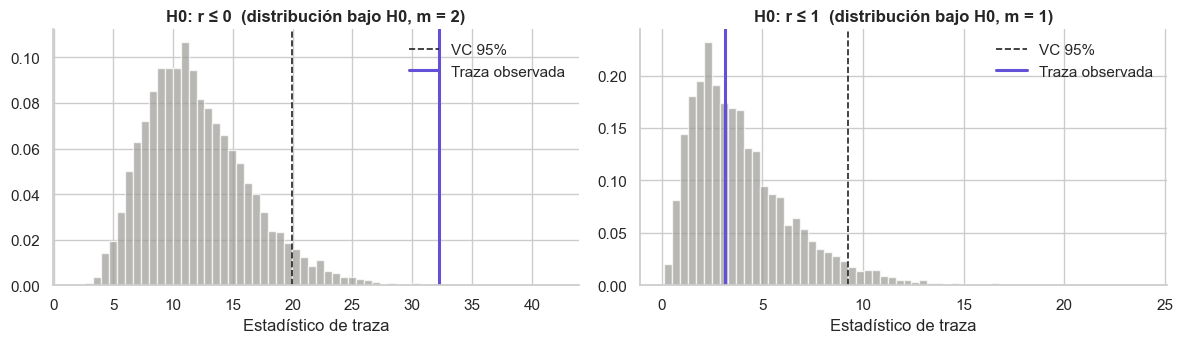

In [9]:
k = y.shape[1]
filas = []
for r0 in range(k):
    m = k - r0
    est = j_ci["traza"][r0]
    filas.append({"H0": f"r ≤ {r0}", "autovalor": j_ci["autovalores"][r0], "Traza": est,
                  "VC 95% (tabla)": VC_TABLA[m][1], "VC 99% (tabla)": VC_TABLA[m][2],
                  "p-valor simulado": (dist_sim[m] >= est).mean(),
                  "Decisión 5%": "rechaza" if est > VC_TABLA[m][1] else "no rechaza"})
tabla_joh = pd.DataFrame(filas).set_index("H0")
display(tabla_joh.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, r0 in zip(axes, (0, 1)):
    m = k - r0
    ax.hist(dist_sim[m], bins=60, color=COL["ref"], alpha=0.7, density=True)
    ax.axvline(VC_TABLA[m][1], color=COL["obs"], ls="--", lw=1.2, label="VC 95%")
    ax.axvline(j_ci["traza"][r0], color=COL["ECT"], lw=2.2, label="Traza observada")
    ax.set_title(f"H0: r ≤ {r0}  (distribución bajo H0, m = {m})"); ax.legend()
    ax.set_xlabel("Estadístico de traza")
plt.tight_layout(); plt.show()

**Interpretación.**

- $H_0: r = 0$ se rechaza con enorme holgura: el estadístico observado está muy a la derecha de toda la distribución
  simulada (p-valor simulado ≈ 0).
- $H_0: r \le 1$ no se rechaza: el estadístico cae en el centro de su distribución bajo la nula.
- **Conclusión: exactamente una relación de cointegración ($r=1$).** Con $r = 1$ queda $k - r = 1$ tendencia estocástica
  común, que podemos asociar al costo mayorista.

### 5.3 ¿Depende de las decisiones del analista?

In [10]:
filas = []
for kd in range(1, 7):
    for caso in ("ci", "co"):
        jj = johansen(y, kd, caso)
        vc = VC_TABLA if caso == "ci" else {2: tuple(coint_johansen(y, 0, kd).cvt[0]), 1: tuple(coint_johansen(y, 0, kd).cvt[1])}
        rango = 0 if jj["traza"][0] <= vc[2][1] else (1 if jj["traza"][1] <= vc[1][1] else 2)
        filas.append({"k_ar_diff": kd, "constante": caso, "Traza r≤0": jj["traza"][0], "VC95 r≤0": vc[2][1],
                      "Traza r≤1": jj["traza"][1], "VC95 r≤1": vc[1][1], "r elegido (5%)": rango})
display(pd.DataFrame(filas).round(2))

,k_ar_diff,constante,Traza r≤0,VC95 r≤0,Traza r≤1,VC95 r≤1,r elegido (5%)
0,1,ci,42.32,19.96,2.71,9.24,1
1,1,co,42.28,15.49,2.68,3.84,1
2,2,ci,38.47,19.96,2.95,9.24,1
3,2,co,38.44,15.49,2.93,3.84,1
4,3,ci,32.22,19.96,3.17,9.24,1
5,3,co,32.17,15.49,3.15,3.84,1
6,4,ci,29.74,19.96,3.74,9.24,1
7,4,co,29.68,15.49,3.73,3.84,1
8,5,ci,27.66,19.96,3.52,9.24,1
9,5,co,27.61,15.49,3.51,3.84,1


**Lectura.** Con 1 a 6 rezagos y con cualquiera de las dos formas de incluir la constante, la prueba elige $r = 1$ al 5 %.
A diferencia de muchos ejemplos reales, aquí el rango **no depende** de las decisiones del analista: es un resultado robusto.

> **Error frecuente.** Decidir el rango con `coint_johansen(det_order=0)` y estimar luego con `deterministic="ci"` sin
> advertir que son especificaciones distintas. Aquí ambas coinciden en $r=1$, pero no siempre ocurre.

---
## Módulo 6. Estimación e interpretación del VECM

**Objetivo de aprendizaje:** leer $\hat\beta$, la constante, $\hat\alpha$ y $\hat\Gamma$ en términos económicos.

Especificación: $r=1$, `k_ar_diff = 3`, `deterministic = "ci"`, variables en USD/galón.

In [11]:
vecm_res = VECM(y, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
b2, mu0 = vecm_res.beta[1, 0], vecm_res.det_coef_coint[0, 0]
ic_b2 = vecm_res.conf_int_beta(alpha=0.05)[1, 0]
ic_mu = vecm_res.conf_int_det_coef_coint(alpha=0.05)[0, 0]
print(f"Observaciones efectivas: {vecm_res.nobs}")

tabla_lp = pd.DataFrame({
    "estimación": [1.0, b2, mu0],
    "error est.": [np.nan, vecm_res.stderr_beta[1, 0], vecm_res.stderr_det_coef_coint[0, 0]],
    "IC95 inf": [np.nan, ic_b2[0], ic_mu[0]], "IC95 sup": [np.nan, ic_b2[1], ic_mu[1]],
}, index=["β minorista (normalizado)", "β mayorista", "constante μ₀"])
print("Relación de cointegración: ECT = minorista + β₂·mayorista + μ₀")
display(tabla_lp.round(4))
print(f"Equilibrio: minorista = {-mu0:.3f} + {-b2:.3f} × mayorista   (USD/galón)")

tabla_alpha = pd.DataFrame({"α": vecm_res.alpha[:, 0], "error est.": vecm_res.stderr_alpha[:, 0],
                            "z": vecm_res.tvalues_alpha[:, 0], "p-valor": vecm_res.pvalues_alpha[:, 0]},
                           index=["ecuación Δ minorista", "ecuación Δ mayorista"])
display(tabla_alpha.round(4))

Observaciones efectivas: 518
Relación de cointegración: ECT = minorista + β₂·mayorista + μ₀


,estimación,error est.,IC95 inf,IC95 sup
β minorista (normalizado),1.0000,NaN,NaN,NaN
β mayorista,-0.9305,0.0247,-0.9788,-0.8821
constante μ₀,-0.9064,0.0552,-1.0146,-0.7983


Equilibrio: minorista = 0.906 + 0.930 × mayorista   (USD/galón)


,α,error est.,z,p-valor
ecuación Δ minorista,-0.0846,0.021,-4.0265,0.0001
ecuación Δ mayorista,-0.0202,0.041,-0.4930,0.6220


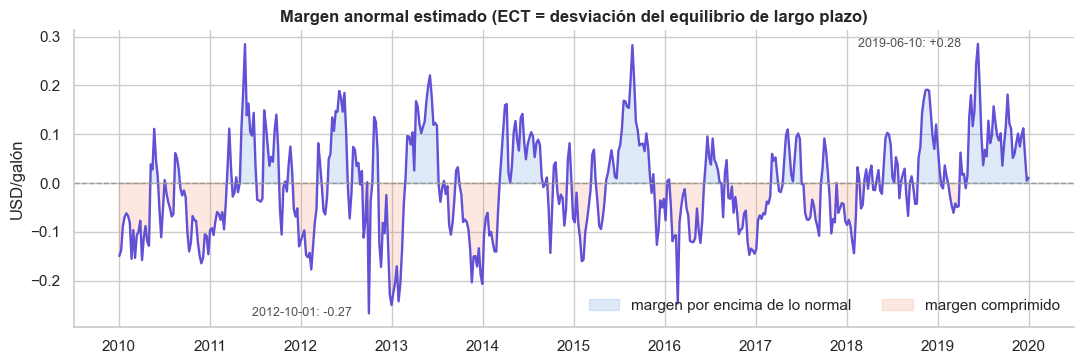

Desviación estándar del ECT: 0.097 USD/galón


In [12]:
ect = pd.Series(y.values @ vecm_res.beta[:, 0] + mu0, index=y.index, name="ECT")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ect.index, ect, color=COL["ECT"])
ax.axhline(0, color=COL["ref"], ls="--", lw=1)
ax.fill_between(ect.index, ect, 0, where=ect > 0, color=COL["minorista"], alpha=0.15, label="margen por encima de lo normal")
ax.fill_between(ect.index, ect, 0, where=ect < 0, color=COL["mayorista"], alpha=0.15, label="margen comprimido")
for f in (ect.idxmax(), ect.idxmin()):
    ax.annotate(f"{f:%Y-%m-%d}: {ect[f]:+.2f}", (f, ect[f]), xytext=(-12, 0), textcoords="offset points",
                fontsize=9, color="#52514e", va="center", ha="right")
ax.set_ylabel("USD/galón"); ax.set_title("Margen anormal estimado (ECT = desviación del equilibrio de largo plazo)")
ax.legend(loc="lower right", ncol=2); eje_fechas(ax)
plt.tight_layout(); plt.show()
print(f"Desviación estándar del ECT: {ect.std():.3f} USD/galón")

### 6.1 Relación de largo plazo ($\beta$ y constante)

El equilibrio estimado es, aproximadamente, **minorista ≈ 0.91 + 0.93 × mayorista** (USD/galón).

- **Constante (≈ 0.91 USD/galón).** Es lo que separa en promedio el surtidor del mayorista cuando el mayorista vale
  "cero". Recoge impuestos por galón (federal 0.184 más estatales, del orden de 0.30 en promedio en la década) y el costo
  típico de distribución y venta minorista. Su orden de magnitud es el que la contabilidad del sector sugiere: el número
  tiene sentido económico.
- **Pendiente (≈ 0.93).** Un aumento permanente de 10 centavos en el mayorista se asocia en el largo plazo con un aumento de
  ≈ 9.3 centavos en el surtidor. El intervalo de confianza al 95 % (≈ 0.88-0.98) **no incluye el 1**: el traslado de largo
  plazo es alto pero no completo. Una explicación plausible (que este análisis no prueba) es que la gasolina que se vende al
  público es E10, con ≈ 10 % de etanol, cuyo precio no está atado uno a uno al de la gasolina convencional de Nueva York;
  otra, que el promedio nacional mezcla regiones cuyo costo mayorista no es exactamente el de NY Harbor.
- **Normalización ≠ causalidad.** Escribir la relación "despejando" el minorista es natural aquí, pero la normalización por
  sí sola no demuestra que el mayorista cause al minorista; eso lo sugieren $\alpha$ y la teoría.

### 6.2 Velocidades de ajuste ($\alpha$)

- $\hat\alpha_{min}\approx -0.085$ y muy significativo: si esta semana el margen está 10 centavos por encima de lo normal,
  la semana siguiente el precio en surtidor baja, en promedio, ≈ 0.85 centavos solo por este canal. El minorista **corrige**.
- $\hat\alpha_{may}\approx -0.02$ y no significativo: el mayorista **no reacciona** a los márgenes de las estaciones.
  No se rechaza la **exogeneidad débil** del mayorista: H2 se confirma.

La gráfica del ECT muestra episodios de margen alto tras caídas del mayorista (mediados de 2011, verano de 2015, finales de 2018,
mediados de 2019) y márgenes comprimidos tras subidas bruscas (otoño de 2012, el mínimo de la muestra). Que los márgenes altos
parezcan durar más que los comprimidos anticipa la asimetría del Módulo 9.

### 6.3 ¿Cuánto tarda en cerrarse una brecha?

Con 3 rezagos en diferencias, la fórmula simple $\ln 0.5/\ln(1+\beta'\alpha)$ ignora la dinámica de $\Gamma$ y no es válida.
Calculamos la trayectoria completa: partimos del equilibrio, subimos el minorista 10 centavos por encima del nivel de
equilibrio y dejamos evolucionar el sistema estimado **sin nuevos choques**.

β'α = -0.0659; fórmula simple (incorrecta con Γ ≠ 0): 10.2 semanas
Dinámica completa: la brecha se reduce a la mitad en 7 semanas y al 10 % en 19 semanas


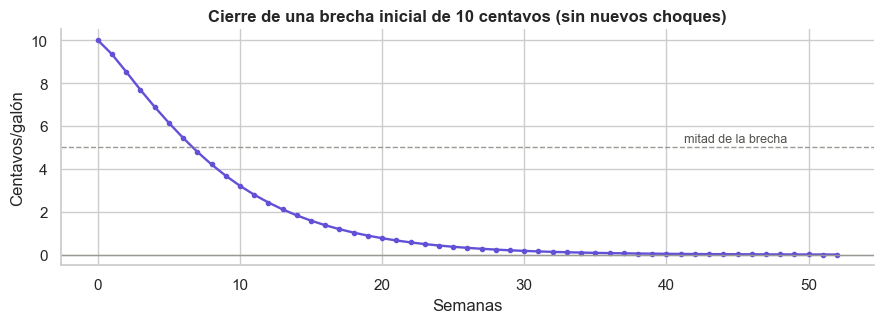

In [13]:
def trayectoria_desequilibrio(res, brecha=0.10, semanas=52):
    # Simula el VECM estimado sin choques desde un desequilibrio inicial en la primera variable
    a, b, m0, G = res.alpha, res.beta, res.det_coef_coint[0, 0], res.gamma
    k, p = a.shape[0], res.k_ar - 1
    y_eq = np.array([-(m0 + b[1, 0] * 3.0), 3.0])              # punto de equilibrio con mayorista = 3 USD
    nivel = y_eq + np.array([brecha, 0.0])
    difs = [np.zeros(k) for _ in range(p)]                      # cambios pasados nulos
    ect_path = [float(b[:, 0] @ nivel + m0)]
    for _ in range(semanas):
        d = (a @ (b.T @ nivel + m0)).ravel()
        for i in range(p):
            d += G[:, i * k:(i + 1) * k] @ difs[i]
        nivel = nivel + d
        difs = [d] + difs[:-1]
        ect_path.append(float(b[:, 0] @ nivel + m0))
    return np.array(ect_path)

camino = trayectoria_desequilibrio(vecm_res)
semivida = int(np.argmax(np.abs(camino) <= 0.5 * abs(camino[0])))
s90 = int(np.argmax(np.abs(camino) <= 0.1 * abs(camino[0])))
ba = (vecm_res.beta.T @ vecm_res.alpha).item()
print(f"β'α = {ba:.4f}; fórmula simple (incorrecta con Γ ≠ 0): {np.log(0.5) / np.log(1 + ba):.1f} semanas")
print(f"Dinámica completa: la brecha se reduce a la mitad en {semivida} semanas y al 10 % en {s90} semanas")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(100 * camino, color=COL["ECT"], marker="o", ms=3)
ax.axhline(5, color=COL["ref"], ls="--", lw=1); ax.axhline(0, color=COL["ref"], lw=1)
ax.annotate("mitad de la brecha", (len(camino) - 1, 5), xytext=(-110, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel("Semanas"); ax.set_ylabel("Centavos/galón")
ax.set_title("Cierre de una brecha inicial de 10 centavos (sin nuevos choques)")
plt.tight_layout(); plt.show()

**Interpretación.** La dinámica completa importa: con los rezagos en diferencias, una brecha de margen se reduce a la mitad en
unas 7 semanas, frente a las ≈ 10 que daría la fórmula simple, y baja al 10 % en unas 19 semanas. Un **margen anormal** se
corrige, por tanto, con lentitud. Contrástelo con el Módulo 8: un **cambio de costo** mayorista llega al surtidor en un 90 % en
unas 4 semanas, porque se traslada sobre todo por los términos $\Gamma$ (cambios mayoristas recientes), no solo por el ECT.
Las estaciones trasladan rápido los cambios de costo, pero dejan que los márgenes altos se disipen despacio, una primera pista
de la asimetría del Módulo 9.

### 6.4 Dinámica de corto plazo ($\Gamma$) y causalidad de Granger

In [14]:
nombres = [f"Δ{c} (t−{l})" for l in range(1, K_AR_DIFF + 1) for c in y.columns]
gam = pd.DataFrame(vecm_res.gamma, index=["ec. Δminorista", "ec. Δmayorista"], columns=nombres)
pg = pd.DataFrame(vecm_res.pvalues_gamma, index=gam.index, columns=nombres)
display(pd.concat({"coef": gam, "p-valor": pg}).round(3))

for causante, causada in ((1, 0), (0, 1)):
    g = vecm_res.test_granger_causality(caused=causada, causing=causante)
    print(f"Granger {y.columns[causante]} → {y.columns[causada]}: p-valor = {g.pvalue:.4f}")

Δminorista (t−1)  Δmayorista (t−1)  Δminorista (t−2)  \
coef    ec. Δminorista             0.186             0.246             0.128   
        ec. Δmayorista            -0.057             0.262             0.102   
p-valor ec. Δminorista             0.003             0.000             0.043   
        ec. Δmayorista             0.642             0.000             0.409   

                        Δmayorista (t−2)  Δminorista (t−3)  Δmayorista (t−3)  
coef    ec. Δminorista            -0.041             0.081            -0.014  
        ec. Δmayorista            -0.105             0.126            -0.118  
p-valor ec. Δminorista             0.252             0.108             0.673  
        ec. Δmayorista             0.134             0.203             0.061

Granger mayorista → minorista: p-valor = 0.0000
Granger minorista → mayorista: p-valor = 0.4277


**Interpretación.**

- En la **ecuación del minorista**, el cambio mayorista de la semana anterior tiene un coeficiente positivo y muy significativo
  (≈ 0.25; los de $t-2$ y $t-3$ no lo son): el costo se traslada con una semana de retraso, además del canal del ECT. El propio cambio minorista
  rezagado también es positivo: las subidas y bajadas en surtidor tienen inercia.
- En la **ecuación del mayorista**, los cambios minoristas pasados no aportan de forma relevante, y la prueba de Granger no
  rechaza que el minorista no lo anticipe. En cambio, el mayorista sí anticipa al minorista (p ≈ 0).
- Todo es coherente con una cadena **mayorista → minorista**. Recuerde que "causalidad de Granger" significa precedencia
  predictiva; aquí coincide con lo que la estructura del mercado haría esperar.

---
## Módulo 7. Diagnóstico y robustez

**Objetivo de aprendizaje:** evaluar los supuestos del VECM y la estabilidad de sus conclusiones.

,Prueba,p-valor,Decisión 5%
0,Portmanteau multivariada (12 rezagos),0.0701,no rechaza H0
1,Jarque-Bera multivariada,0.0000,rechaza H0
2,Ljung-Box (12) — minorista,0.4927,no rechaza H0
3,ARCH-LM (4) — minorista,0.0055,rechaza H0
4,Ljung-Box (12) — mayorista,0.3084,no rechaza H0
5,ARCH-LM (4) — mayorista,0.0032,rechaza H0


Asimetría y curtosis (exceso):


,asimetría,curtosis
minorista,1.02,5.15
mayorista,-0.07,1.71


Semanas con |residuo estandarizado| > 4:


,minorista,mayorista
fecha_lunes,,
2011-02-28,4.49,3.29
2012-08-06,4.10,2.49
2012-10-01,0.53,4.27
2017-09-04,6.64,4.01


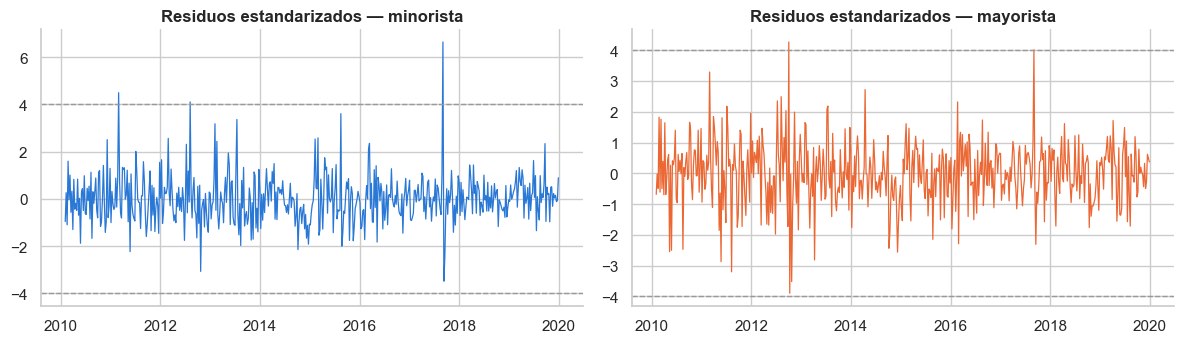

In [15]:
residuos = pd.DataFrame(vecm_res.resid, index=y.index[K_AR_DIFF + 1:], columns=y.columns)
assert len(residuos) == vecm_res.nobs
z = (residuos - residuos.mean()) / residuos.std()

diag = [{"Prueba": "Portmanteau multivariada (12 rezagos)", "p-valor": vecm_res.test_whiteness(nlags=12, adjusted=True).pvalue},
        {"Prueba": "Jarque-Bera multivariada", "p-valor": vecm_res.test_normality().pvalue}]
for c in y.columns:
    diag.append({"Prueba": f"Ljung-Box (12) — {c}", "p-valor": acorr_ljungbox(residuos[c], lags=[12])["lb_pvalue"].iloc[0]})
    diag.append({"Prueba": f"ARCH-LM (4) — {c}", "p-valor": het_arch(residuos[c], nlags=4)[1]})
tabla_diag = pd.DataFrame(diag)
tabla_diag["Decisión 5%"] = np.where(tabla_diag["p-valor"] < 0.05, "rechaza H0", "no rechaza H0")
display(tabla_diag.round(4))
print("Asimetría y curtosis (exceso):")
display(pd.DataFrame({"asimetría": residuos.skew(), "curtosis": residuos.kurt()}).round(2))
print("Semanas con |residuo estandarizado| > 4:")
display(z[(z.abs() > 4).any(axis=1)].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, c in zip(axes, y.columns):
    ax.plot(z.index, z[c], color=COL[c], lw=0.9)
    for lim in (-4, 4):
        ax.axhline(lim, color=COL["ref"], ls="--", lw=1)
    ax.set_title(f"Residuos estandarizados — {c}"); eje_fechas(ax, 2)
plt.tight_layout(); plt.show()

**Interpretación.** No hay autocorrelación residual (condición clave para la validez de Johansen y de los errores
estándar). En cambio, se rechazan la normalidad y la homocedasticidad: los residuos tienen colas pesadas y agrupamiento de
volatilidad, como es habitual en precios de energía. El residuo más extremo, en ambas ecuaciones, es la semana del 4 de
septiembre de 2017 (huracán Harvey); los demás corresponden a interrupciones de suministro de 2011 y 2012. Esto no sesga
$\hat\beta$, pero sí vuelve poco fiables los intervalos de pronóstico gaussianos.

### 7.1 Sensibilidad a rezagos y constante

In [16]:
filas = []
for kd in range(1, 7):
    for det in ("ci", "co"):
        r_ = VECM(y, k_ar_diff=kd, coint_rank=1, deterministic=det).fit()
        filas.append({"k_ar_diff": kd, "constante": det, "−β₂": -r_.beta[1, 0],
                      "μ₀ (solo ci)": r_.det_coef_coint[0, 0] if det == "ci" else np.nan,
                      "α minorista": r_.alpha[0, 0], "p α min": r_.pvalues_alpha[0, 0],
                      "α mayorista": r_.alpha[1, 0], "p α may": r_.pvalues_alpha[1, 0],
                      "p Portmanteau": r_.test_whiteness(nlags=12, adjusted=True).pvalue})
display(pd.DataFrame(filas).round(3))

,k_ar_diff,constante,−β₂,μ₀ (solo ci),α minorista,p α min,α mayorista,p α may,p Portmanteau
0,1,ci,0.950,-0.863,-0.076,0.0,0.025,0.507,0.000
1,1,co,0.950,NaN,-0.076,0.0,0.025,0.508,0.000
2,2,ci,0.938,-0.890,-0.082,0.0,0.002,0.957,0.054
3,2,co,0.938,NaN,-0.082,0.0,0.002,0.959,0.054
4,3,ci,0.930,-0.906,-0.085,0.0,-0.020,0.622,0.070
5,3,co,0.930,NaN,-0.085,0.0,-0.020,0.619,0.070
6,4,ci,0.925,-0.919,-0.084,0.0,-0.026,0.535,0.074
7,4,co,0.925,NaN,-0.084,0.0,-0.026,0.532,0.074
8,5,ci,0.926,-0.917,-0.083,0.0,-0.026,0.543,0.034
9,5,co,0.926,NaN,-0.083,0.0,-0.026,0.539,0.034


**Lectura.** Las conclusiones son estables: $-\beta_2$ entre ≈ 0.92 y ≈ 0.95, constante entre ≈ 0.86 y ≈ 0.92 USD/galón,
$\alpha$ del minorista negativo y muy significativo en todas las variantes, y $\alpha$ del mayorista nunca significativo. La
especificación de la constante (`ci` frente a `co`) prácticamente no cambia nada.

### 7.2 Estabilidad en el tiempo (estimación recursiva)

C:\Users\wsand\AppData\Local\Temp\ipykernel_30516\30561940.py:19: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\wsand\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


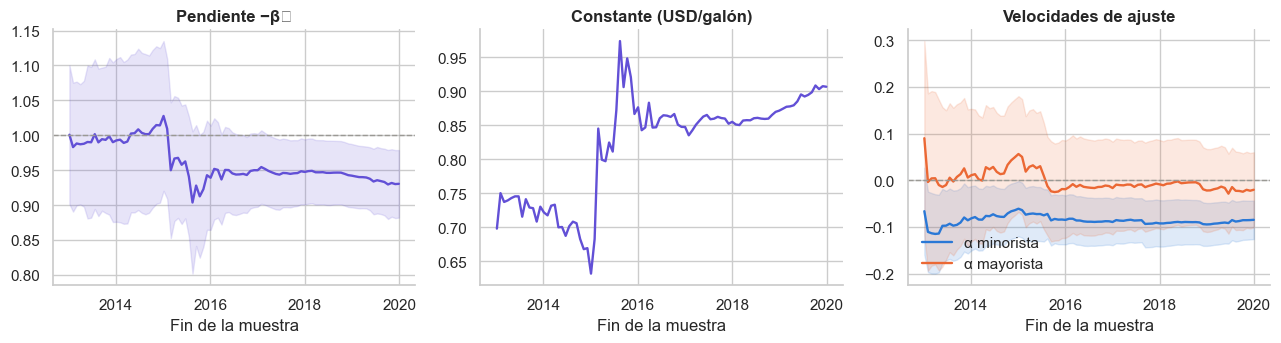

In [17]:
rec = []
for fin in y.loc["2013-01-01":].index[::4]:
    r_ = VECM(y.loc[:fin], k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
    rec.append({"fin": fin, "b": -r_.beta[1, 0], "se_b": r_.stderr_beta[1, 0], "mu": -r_.det_coef_coint[0, 0],
                "a_min": r_.alpha[0, 0], "se_min": r_.stderr_alpha[0, 0], "a_may": r_.alpha[1, 0], "se_may": r_.stderr_alpha[1, 0]})
rec = pd.DataFrame(rec).set_index("fin")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(rec.index, rec["b"], color=COL["ECT"])
axes[0].fill_between(rec.index, rec["b"] - 1.96 * rec["se_b"], rec["b"] + 1.96 * rec["se_b"], color=COL["ECT"], alpha=0.15)
axes[0].axhline(1, color=COL["ref"], ls="--", lw=1); axes[0].set_title("Pendiente −β₂")
axes[1].plot(rec.index, rec["mu"], color=COL["ECT"]); axes[1].set_title("Constante (USD/galón)")
for nom, se, c, etq in (("a_min", "se_min", COL["minorista"], "α minorista"), ("a_may", "se_may", COL["mayorista"], "α mayorista")):
    axes[2].plot(rec.index, rec[nom], color=c, label=etq)
    axes[2].fill_between(rec.index, rec[nom] - 1.96 * rec[se], rec[nom] + 1.96 * rec[se], color=c, alpha=0.15)
axes[2].axhline(0, color=COL["ref"], ls="--", lw=1); axes[2].set_title("Velocidades de ajuste"); axes[2].legend(loc="lower left")
for ax in axes:
    ax.set_xlabel("Fin de la muestra"); eje_fechas(ax, 2)
plt.tight_layout(); plt.show()

**Interpretación.**

- **Ajuste (α): muy estable.** El $\alpha$ minorista es negativo con banda alejada de cero en todas las muestras, y el del
  mayorista siempre incluye el cero. La conclusión "el minorista corrige, el mayorista no" no depende del período.
- **Relación de largo plazo: un cambio en 2015.** Con muestras que terminan antes de 2015, la pendiente es ≈ 1 (la banda incluye
  el 1) y la constante ≈ 0.70-0.75 USD/galón. Al incorporar la caída del petróleo de 2014-2015, la constante salta a ≈ 0.85-0.90
  y la pendiente baja a ≈ 0.93-0.95. Es coherente con un hecho conocido del sector: tras 2015 los márgenes minoristas se
  ampliaron de forma persistente. Parte de la pendiente menor que 1 del Módulo 6 podría reflejar ese desplazamiento del margen
  más que un traslado incompleto.
- Implicación práctica: la relación es suficientemente estable para el análisis, pero un estudio aplicado debería probar un
  quiebre en la constante (por ejemplo, con una variable ficticia restringida a la relación desde 2015). Queda como ejercicio.

> **Comprueba tu comprensión.** ¿Por qué la ausencia de autocorrelación residual es más importante que la normalidad para
> confiar en la prueba de Johansen?

---
## Módulo 8. Funciones impulso-respuesta: el traslado del costo al surtidor

**Objetivo de aprendizaje:** medir cómo y en cuánto tiempo un cambio mayorista llega al precio en surtidor.

Para identificar choques usamos Cholesky con el **mayorista primero**: puede afectar al minorista en la misma semana, pero no al
revés. Es un supuesto razonable por la estructura del mercado y porque el promedio mayorista se calcula con los días previos
al lunes en que se mide el minorista. Las IRF no son invariantes al orden y la correlación entre los
residuos es alta (≈ 0.74), así que este supuesto pesa sobre todo en la respuesta del primer período. `statsmodels` no calcula bandas de confianza para IRF de un VECM, así que se
presentan estimaciones puntuales.

Correlación de residuos: 0.740


C:\Users\wsand\AppData\Local\Temp\ipykernel_30516\1507761964.py:21: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\wsand\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


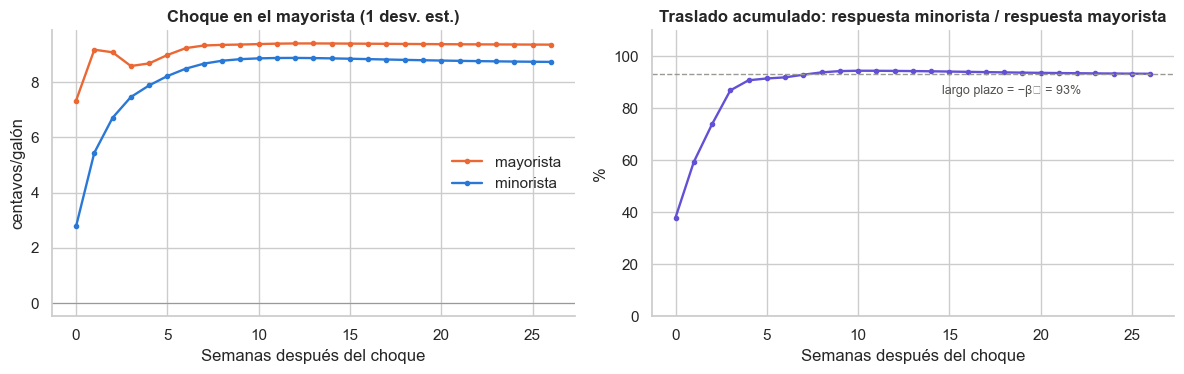

semana,0,1,2,4,8,12,26
traslado acumulado %,38.0,59.4,73.9,90.8,93.9,94.4,93.3


Choque propio del minorista: efecto en h=0 = 2.53 ¢; en h=26 = -0.58 ¢; efecto sobre el mayorista en h=26 = -0.77 ¢


In [18]:
H = 26
# Mismo modelo con el orden (mayorista, minorista) para la identificación de Cholesky
res_ord = VECM(y[["mayorista", "minorista"]], k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
oirf = res_ord.irf(periods=H).orth_irfs            # [h, respuesta, choque]; 0 = mayorista, 1 = minorista
print(f"Correlación de residuos: {np.corrcoef(vecm_res.resid.T)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(100 * oirf[:, 0, 0], color=COL["mayorista"], marker="o", ms=3, label="mayorista")
axes[0].plot(100 * oirf[:, 1, 0], color=COL["minorista"], marker="o", ms=3, label="minorista")
axes[0].set_title("Choque en el mayorista (1 desv. est.)"); axes[0].set_ylabel("centavos/galón")
traspaso = oirf[:, 1, 0] / oirf[:, 0, 0]
axes[1].plot(100 * traspaso, color=COL["ECT"], marker="o", ms=3)
axes[1].axhline(100 * -b2, color=COL["ref"], ls="--", lw=1)
axes[1].annotate(f"largo plazo = −β₂ = {-b2:.0%}", (H, 100 * -b2), xytext=(-150, -14), textcoords="offset points",
                 fontsize=9, color="#52514e")
axes[1].set_title("Traslado acumulado: respuesta minorista / respuesta mayorista"); axes[1].set_ylabel("%")
axes[1].set_ylim(0, 110)
for ax in axes:
    ax.set_xlabel("Semanas después del choque"); ax.axhline(0, color=COL["ref"], lw=0.8)
axes[0].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"semana": [0, 1, 2, 4, 8, 12, 26],
                      "traslado acumulado %": [round(100 * traspaso[h], 1) for h in (0, 1, 2, 4, 8, 12, 26)]}).set_index("semana").T)

# Respuesta a un choque propio del minorista (margen)
print(f"Choque propio del minorista: efecto en h=0 = {100 * oirf[0, 1, 1]:.2f} ¢; en h=26 = {100 * oirf[-1, 1, 1]:.2f} ¢; "
      f"efecto sobre el mayorista en h=26 = {100 * oirf[-1, 0, 1]:.2f} ¢")

**Interpretación.**

- Un choque típico al mayorista (≈ 7 centavos, que se estabiliza en ≈ 9) es **permanente** y se traslada al minorista de forma
  gradual: ≈ 38 % en la misma semana (cifra que depende del orden de Cholesky), ≈ 60 % a la semana siguiente, ≈ 90 % a las
  4 semanas, y converge al valor de largo plazo $-\hat\beta_2 \approx 93\%$, como exige la relación de cointegración.
- Un choque propio del minorista (por ejemplo, una guerra de precios local o un cambio de margen) es casi **transitorio**: su
  efecto de largo plazo sobre ambos precios es menor de 1 centavo. Eso es lo que significa que el mayorista sea la tendencia común del sistema.
- Este perfil (traslado lento y completo en ≈ dos meses) es el núcleo empírico del debate sobre el poder de mercado de las
  estaciones de servicio.

### 8.1 Descomposición de varianza (FEVD)

Calculada a partir de las respuestas ortogonalizadas del VECM (statsmodels no ofrece `fevd` para VECM); la fórmula se
comprueba antes contra la implementación de statsmodels en un VAR.

In [19]:
def fevd_desde_oirf(orth):
    acum = np.cumsum(orth ** 2, axis=0)
    return acum / acum.sum(axis=2, keepdims=True)

v_chk = VAR(y).fit(2)
print("Verificación con un VAR:", np.allclose(np.transpose(v_chk.fevd(H).decomp, (1, 0, 2)), fevd_desde_oirf(v_chk.irf(H).orth_irfs)[:H]))
fe = fevd_desde_oirf(oirf)
display(pd.DataFrame({f"h={h}": [100 * fe[h - 1, 1, 0], 100 * fe[h - 1, 0, 0]] for h in (1, 4, 8, 26)},
                     index=["% var. minorista por choques mayoristas", "% var. mayorista por choques mayoristas"]).round(1))

Verificación con un VAR: True


,h=1,h=4,h=8,h=26
% var. minorista por choques mayoristas,54.8,81.8,88.3,96.6
% var. mayorista por choques mayoristas,100.0,100.0,99.9,99.7


**Interpretación.** Ya a una semana, algo más de la mitad (≈ 55 %) de la incertidumbre del precio minorista proviene de choques
mayoristas; a 4 semanas, ≈ 82 %, y a 26 semanas, ≈ 97 %. La varianza del mayorista se explica casi
por completo por sus propios choques en todos los horizontes. A largo plazo, **quien manda es el mayorista**.

---
## Módulo 9. Extensión: ¿cohetes y plumas?

**Objetivo de aprendizaje:** usar el término de corrección del error para contrastar una hipótesis económica de asimetría.

El VECM lineal impone que el minorista responda igual a subidas y bajadas. La hipótesis de "cohetes y plumas" dice lo
contrario: **los precios suben rápido y bajan despacio**. Siguiendo a Borenstein, Cameron y Gilbert (1997), estimamos una
ecuación de corrección del error **asimétrica** para el minorista, separando:

- $ECT^+_{t-1} = \max(ECT_{t-1},0)$ (margen alto) y $ECT^-_{t-1} = \min(ECT_{t-1},0)$ (margen comprimido);
- $\Delta P^{may+}_{t-j}$ y $\Delta P^{may-}_{t-j}$ (subidas y bajadas del mayorista).

$$\Delta P^{min}_t = c + \theta^+ECT^+_{t-1} + \theta^-ECT^-_{t-1}
+ \sum_{j=0}^{3}\big(\gamma^+_j\Delta P^{may+}_{t-j} + \gamma^-_j\Delta P^{may-}_{t-j}\big)
+ \sum_{j=1}^{3}\phi_j\Delta P^{min}_{t-j} + u_t$$

Incluir $\Delta P^{may}_t$ contemporáneo es legítimo en esta ecuación condicional porque el mayorista es débilmente exógeno
(Módulo 6) y se mide antes del lunes. Usamos errores estándar robustos a heterocedasticidad (HC1), dado el ARCH detectado.

In [20]:
dR, dW = y["minorista"].diff(), y["mayorista"].diff()
X = pd.DataFrame({"ECT+ (t−1)": ect.shift(1).clip(lower=0), "ECT− (t−1)": ect.shift(1).clip(upper=0)})
for j in range(4):
    X[f"ΔW+ (t−{j})"] = dW.shift(j).clip(lower=0)
    X[f"ΔW− (t−{j})"] = dW.shift(j).clip(upper=0)
for j in range(1, 4):
    X[f"ΔR (t−{j})"] = dR.shift(j)
datos_asim = pd.concat([dR.rename("ΔR"), X], axis=1).dropna()
mod_asim = sm.OLS(datos_asim["ΔR"], sm.add_constant(datos_asim.drop(columns="ΔR"))).fit(cov_type="HC1")

coef = pd.DataFrame({"coef": mod_asim.params, "p-valor": mod_asim.pvalues}).drop("const")
display(coef.round(3))

def wald_igualdad(izq, der):
    # Contraste de Wald de  Σ coef(izq) = Σ coef(der)  con la matriz de covarianzas robusta
    nombres_x = list(mod_asim.params.index)
    R = np.zeros((1, len(nombres_x)))
    for t in izq: R[0, nombres_x.index(t)] += 1
    for t in der: R[0, nombres_x.index(t)] -= 1
    w = mod_asim.wald_test(R, scalar=True)
    return float(w.statistic), float(w.pvalue)

pos = [f"ΔW+ (t−{j})" for j in range(4)]; neg = [f"ΔW− (t−{j})" for j in range(4)]
pruebas = {"θ+ = θ− (corrección de márgenes altos vs. bajos)": (["ECT+ (t−1)"], ["ECT− (t−1)"]),
           "γ0+ = γ0− (traslado en la misma semana)": ([pos[0]], [neg[0]]),
           "Σγ+ = Σγ− (traslado acumulado a 4 semanas)": (pos, neg)}
filas = [{"Hipótesis nula": n, "Wald χ²": wald_igualdad(*t)[0], "p-valor": wald_igualdad(*t)[1]} for n, t in pruebas.items()]
display(pd.DataFrame(filas).round(4))
suma_pos = mod_asim.params[[f"ΔW+ (t−{j})" for j in range(4)]].sum()
suma_neg = mod_asim.params[[f"ΔW− (t−{j})" for j in range(4)]].sum()
print(f"Traslado acumulado a 4 semanas: subidas {suma_pos:.2f} | bajadas {suma_neg:.2f}")

,coef,p-valor
ECT+ (t−1),-0.026,0.322
ECT− (t−1),-0.120,0.000
ΔW+ (t−0),0.495,0.000
ΔW− (t−0),0.268,0.000
ΔW+ (t−1),0.109,0.031
ΔW− (t−1),0.174,0.000
ΔW+ (t−2),-0.019,0.643
ΔW− (t−2),0.041,0.197
ΔW+ (t−3),-0.031,0.401
ΔW− (t−3),0.072,0.015


,Hipótesis nula,Wald χ²,p-valor
0,θ+ = θ− (corrección de márgenes altos vs. bajos),4.3196,0.0377
1,γ0+ = γ0− (traslado en la misma semana),7.9686,0.0048
2,Σγ+ = Σγ− (traslado acumulado a 4 semanas),0.0004,0.9848


Traslado acumulado a 4 semanas: subidas 0.55 | bajadas 0.56


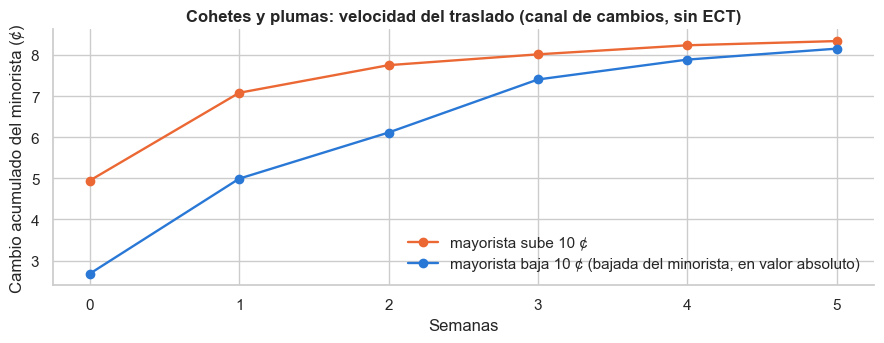

In [21]:
# Respuesta acumulada del minorista a una subida y a una bajada de 10 centavos del mayorista
# (solo canal de ΔW y ΔR rezagados, sin ECT, para visualizar la velocidad de los primeros días)
def respuesta_acumulada(signo, semanas=6):
    g = [mod_asim.params[f"ΔW{signo} (t−{j})"] for j in range(4)]
    phi = [mod_asim.params[f"ΔR (t−{j})"] for j in range(1, 4)]
    dRs = []
    for t in range(semanas):
        v = (g[t] if t < 4 else 0) * 0.10
        v += sum(phi[j - 1] * dRs[t - j] for j in range(1, 4) if t - j >= 0)
        dRs.append(v)
    return 100 * np.cumsum(dRs)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(respuesta_acumulada("+"), marker="o", color=COL["mayorista"], label="mayorista sube 10 ¢")
ax.plot(respuesta_acumulada("−"), marker="o", color=COL["minorista"], label="mayorista baja 10 ¢ (bajada del minorista, en valor absoluto)")
ax.set_xlabel("Semanas"); ax.set_ylabel("Cambio acumulado del minorista (¢)")
ax.set_title("Cohetes y plumas: velocidad del traslado (canal de cambios, sin ECT)"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación.**

- **Traslado inmediato asimétrico ("cohetes").** En la misma semana, una subida del mayorista se traslada aproximadamente el
  doble que una bajada, y la diferencia es significativa. Las subidas llegan rápido al surtidor.
- **Traslado acumulado simétrico.** Al cabo de cuatro semanas, el traslado total de subidas y bajadas es prácticamente igual:
  la asimetría es de **velocidad**, no de nivel final.
- **Corrección asimétrica de márgenes ("plumas").** Cuando el margen está comprimido ($ECT<0$), el minorista lo recupera con
  rapidez ($\theta^-$ grande y significativo); cuando el margen está alto ($ECT>0$), la corrección es lenta y no significativa
  ($\theta^+$ pequeño). La igualdad $\theta^+=\theta^-$ se rechaza al 5 %.

Ambos resultados apuntan en la dirección de la hipótesis de cohetes y plumas. **Limitaciones:** el ECT es un regresor generado
(estimado en el VECM), lo que hace que los errores estándar sean aproximados; y la ecuación es de forma reducida, no identifica
por qué existe la asimetría (costos de búsqueda de los consumidores, colusión tácita, gestión de inventarios…).

> **Comprueba tu comprensión.** ¿Por qué un VECM lineal no puede detectar esta asimetría por sí solo? ¿Qué parte del VECM
> hubo que modificar?

---
## Módulo 10. Pronóstico con validación temporal

**Objetivo de aprendizaje:** comprobar fuera de muestra si la estructura de corrección del error mejora los pronósticos, y para
qué variable.

| Conjunto | Período | Uso |
|---|---|---|
| Entrenamiento | 2010-2016 | Estimación inicial |
| Validación | 2017-2018 | Elegir rezagos dentro de cada familia de modelos |
| Prueba | 2019 | Evaluación final (una sola vez) |

Origen móvil con ventana expansiva: en cada semana de origen se reestima cada modelo con los datos **anteriores** a esa semana
y se pronostican $h = 1,\dots,8$ semanas. Modelos: VECM (`ci`, $r=1$), VAR en diferencias, VAR en niveles y modelo ingenuo
(último valor observado). Errores en USD/galón.

In [22]:
INI_VAL, FIN_VAL = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-12-31")
INI_TEST, FIN_TEST = pd.Timestamp("2019-01-01"), y.index[-1]
H_MAX = 8

def pronosticar(modelo, p, hist, h):
    if modelo == "VECM":
        return VECM(hist, k_ar_diff=p, coint_rank=1, deterministic="ci").fit().predict(steps=h)
    if modelo == "VAR_dif":
        d = hist.diff().dropna(); r = VAR(d).fit(p, trend="c")
        return hist.values[-1] + np.cumsum(r.forecast(d.values[-p:], h), axis=0)
    if modelo == "VAR_niv":
        r = VAR(hist).fit(p, trend="c"); return r.forecast(hist.values[-p:], h)
    if modelo == "Ingenuo":
        return np.repeat(hist.values[-1:], h, axis=0)
    raise ValueError(modelo)

def origen_movil(modelo, p, ini, fin):
    filas, idx = [], y.index
    for origen in idx[(idx >= ini) & (idx <= fin)]:
        pos = idx.get_loc(origen)
        f = pronosticar(modelo, p, y.iloc[:pos], H_MAX)          # solo información anterior al origen
        for h in range(H_MAX):
            if pos + h < len(idx) and idx[pos + h] <= fin:
                real = y.iloc[pos + h].values
                filas.append({"modelo": modelo, "p": p, "objetivo": idx[pos + h], "h": h + 1,
                              "pred_min": f[h, 0], "pred_may": f[h, 1], "e_min": real[0] - f[h, 0], "e_may": real[1] - f[h, 1]})
    return pd.DataFrame(filas)

rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
CANDIDATOS = {"VECM": [1, 2, 3, 4], "VAR_dif": [1, 2, 3, 4], "VAR_niv": [2, 3, 4, 5], "Ingenuo": [0]}
val = pd.concat([origen_movil(m, p, INI_VAL, FIN_VAL) for m, ps in CANDIDATOS.items() for p in ps], ignore_index=True)
tab_val = val.groupby(["modelo", "p"]).agg(RMSE_min=("e_min", rmse), RMSE_may=("e_may", rmse))
tab_val["RMSE promedio"] = tab_val.mean(axis=1)
display(tab_val.round(4))
elegidos = tab_val["RMSE promedio"].groupby(level="modelo").idxmin().map(lambda t: t[1]).to_dict()
print("Configuración elegida en validación:", elegidos)

RMSE_min  RMSE_may  RMSE promedio
modelo  p                                   
Ingenuo 0    0.1237    0.1602         0.1420
VAR_dif 1    0.1228    0.1605         0.1417
        2    0.1255    0.1615         0.1435
        3    0.1263    0.1629         0.1446
        4    0.1275    0.1661         0.1468
VAR_niv 2    0.1175    0.1607         0.1391
        3    0.1194    0.1615         0.1404
        4    0.1207    0.1626         0.1416
        5    0.1234    0.1671         0.1452
VECM    1    0.1193    0.1607         0.1400
        2    0.1210    0.1611         0.1410
        3    0.1218    0.1620         0.1419
        4    0.1239    0.1654         0.1446

Configuración elegida en validación: {'Ingenuo': 0, 'VAR_dif': 1, 'VAR_niv': 2, 'VECM': 1}


Período de prueba 2019, todos los horizontes (USD/galón):


,MAE_min,RMSE_min,MAE_may,RMSE_may,relativo ingenuo_min,relativo ingenuo_may
modelo,,,,,,
Ingenuo,0.1029,0.1448,0.1257,0.1691,1.0000,1.0000
VAR_dif,0.0944,0.1342,0.1271,0.1706,0.9266,1.0087
VAR_niv,0.0906,0.1285,0.1231,0.1636,0.8876,0.9674
VECM,0.0951,0.1362,0.1261,0.1692,0.9407,1.0003


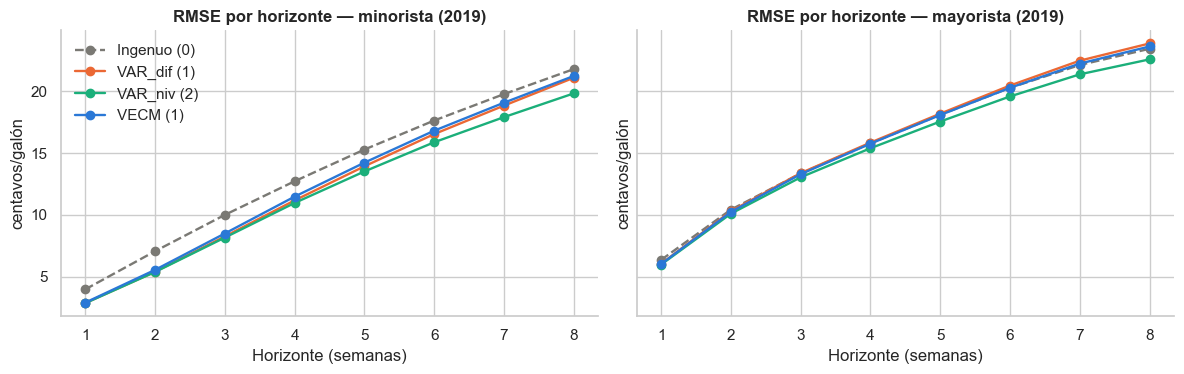

modelo,Ingenuo,VAR_dif,VAR_niv,VECM
"h (minorista, ¢)",,,,
1,3.98,2.87,2.86,2.91
2,7.06,5.40,5.38,5.55
4,12.71,11.17,10.96,11.47
8,21.78,21.08,19.81,21.22


In [23]:
test = pd.concat([origen_movil(m, p, INI_TEST, FIN_TEST) for m, p in elegidos.items()], ignore_index=True)
tab_test = test.groupby("modelo").agg(MAE_min=("e_min", lambda e: e.abs().mean()), RMSE_min=("e_min", rmse),
                                      MAE_may=("e_may", lambda e: e.abs().mean()), RMSE_may=("e_may", rmse))
for c in ("RMSE_min", "RMSE_may"):
    tab_test[c.replace("RMSE", "relativo ingenuo")] = tab_test[c] / tab_test.loc["Ingenuo", c]
print("Período de prueba 2019, todos los horizontes (USD/galón):")
display(tab_test.round(4))

rmse_h = test.groupby(["modelo", "h"]).agg(minorista=("e_min", rmse), mayorista=("e_may", rmse))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, var in zip(axes, ["minorista", "mayorista"]):
    for mod in elegidos:
        ax.plot(rmse_h.loc[mod].index, 100 * rmse_h.loc[mod, var], marker="o", color=COL[mod],
                ls="--" if mod == "Ingenuo" else "-", label=f"{mod} ({elegidos[mod]})")
    ax.set_title(f"RMSE por horizonte — {var} (2019)"); ax.set_xlabel("Horizonte (semanas)"); ax.set_ylabel("centavos/galón")
axes[0].legend()
plt.tight_layout(); plt.show()
display((100 * rmse_h.unstack("modelo")["minorista"].loc[[1, 2, 4, 8]]).round(2).rename_axis("h (minorista, ¢)"))

DM h=1 minorista, VECM vs Ingenuo : estadístico = -3.55, p-valor = 0.0008 (n=52)
DM h=1 minorista, VECM vs VAR_dif : estadístico = +0.30, p-valor = 0.7666 (n=52)
DM h=1 minorista, VECM vs VAR_niv : estadístico = +2.84, p-valor = 0.0065 (n=52)


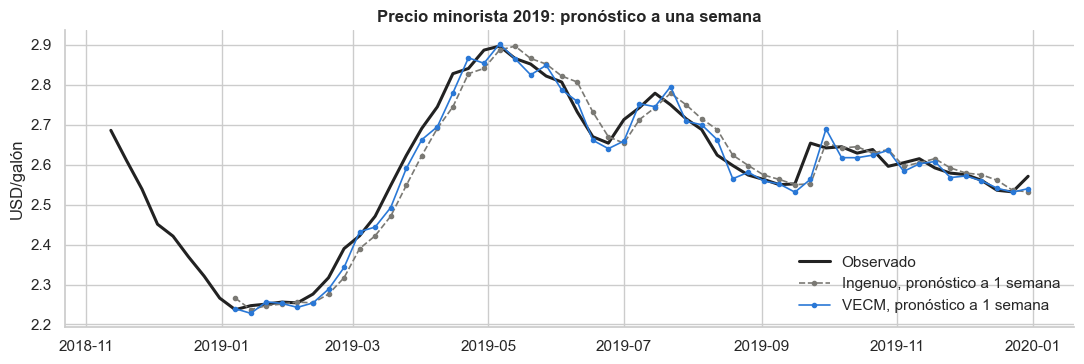

In [24]:
# Diebold-Mariano a una semana para el minorista: VECM frente a cada rival (pérdida cuadrática)
h1 = test[test["h"] == 1].pivot(index="objetivo", columns="modelo", values="e_min") ** 2
for rival in ("Ingenuo", "VAR_dif", "VAR_niv"):
    d = h1["VECM"] - h1[rival]
    est = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    print(f"DM h=1 minorista, VECM vs {rival:<8}: estadístico = {est:+.2f}, p-valor = {2 * (1 - stats.t.cdf(abs(est), len(d) - 1)):.4f} (n={len(d)})")

fig, ax = plt.subplots(figsize=(11, 3.8))
obs = y.loc[INI_TEST - pd.DateOffset(weeks=8):, "minorista"]
ax.plot(obs.index, obs, color=COL["obs"], lw=2.2, label="Observado")
for mod in ("Ingenuo", "VECM"):
    d = test[(test["modelo"] == mod) & (test["h"] == 1)]
    ax.plot(d["objetivo"], d["pred_min"], color=COL[mod], marker="o", ms=3, lw=1.2, ls="--" if mod == "Ingenuo" else "-",
            label=f"{mod}, pronóstico a 1 semana")
ax.set_ylabel("USD/galón"); ax.set_title("Precio minorista 2019: pronóstico a una semana"); ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

**Interpretación.**

- **Minorista:** a 1-2 semanas, el VECM reduce el error frente al modelo ingenuo de forma importante (a una semana, RMSE
  ≈ 2.9 frente a ≈ 4.0 centavos, un 27 % menos), y la prueba de Diebold-Mariano confirma la diferencia. La razón es la que el modelo describe: el minorista **todavía no ha
  absorbido** los cambios mayoristas recientes y el margen anormal, y el VECM aprovecha esa información. El gráfico lo muestra:
  el ingenuo llega siempre una semana tarde; el VECM anticipa parte del movimiento.
- A horizontes más largos la ventaja se reduce y los modelos convergen, porque el error pasa a estar dominado por los choques
  futuros del mayorista, que nadie pronostica.
- **Mayorista:** ningún modelo mejora de forma relevante al ingenuo. Es lo esperable: el mayorista es la tendencia común,
  débilmente exógena, y se comporta casi como un paseo aleatorio.
- **Frente a otros VAR:** el VAR en diferencias obtiene prácticamente el mismo error a una semana, y el VAR en niveles es
  ligeramente mejor en 2019 (con diferencia significativa a una semana, aunque pequeña en centavos). Los tres recogen el
  traslado de los cambios recientes, que es de donde sale casi toda la ganancia. La ventaja del VECM aquí es de
  **interpretación y coherencia** (traslado de largo plazo, márgenes, exogeneidad), no de exactitud frente a todos los rivales.

Lección general: el VECM ayuda a pronosticar **la variable que ajusta**, a **horizontes cortos**. No convierte en predecible a
la variable exógena.

---
## Módulo 11. Conclusiones y limitaciones

| Hipótesis | Resultado | Evidencia |
|---|---|---|
| H1: relación de largo plazo con pendiente ≈ 1 y constante positiva | **Se confirma, con matices** | $r=1$ robusto; minorista ≈ 0.91 + 0.93·mayorista; la pendiente era ≈ 1 antes de 2015 y la constante subió tras 2015 |
| H2: el minorista ajusta y el mayorista es débilmente exógeno | **Se confirma** | $\alpha_{min}<0$ muy significativo; $\alpha_{may}$ nunca significativo; Granger en un solo sentido |
| H3: el traslado tarda semanas | **Se confirma** | IRF: ≈ 60 % a la semana siguiente y ≈ 90 % a las 4 semanas; un margen anormal tarda ≈ 7 semanas en reducirse a la mitad |
| H4: cohetes y plumas | **Evidencia a favor** | Traslado inmediato de subidas ≈ el doble que de bajadas; márgenes comprimidos se corrigen más rápido que los altos |

**Limitaciones.**

1. El precio minorista es un promedio nacional, y el mayorista corresponde a un solo mercado (NY Harbor). Usar el mayorista del
   Golfo de México o promedios regionales puede cambiar las magnitudes.
2. La gasolina minorista incluye etanol y los impuestos cambiaron en algunos estados durante la década; ninguna de las dos
   cosas está modelada.
3. Residuos no normales y con ARCH: los errores estándar son aproximados y los intervalos de pronóstico gaussianos poco fiables.
4. Incluso dentro de 2010-2019 la constante se desplazó en 2015; no se modeló el quiebre. Fuera del período no se garantiza
   que la relación se mantenga.
5. La extensión asimétrica usa un regresor generado y es una forma reducida: describe la asimetría, no su causa.
6. Cointegración y causalidad de Granger describen relaciones estadísticas; la lectura causal (el costo mayorista determina el
   precio minorista) se apoya en la teoría y en la estructura del mercado, no solo en las pruebas.

---
## Módulo 12. Actividades

**Conceptuales**

1. Explique por qué en este sistema hay exactamente una tendencia estocástica común y a qué variable la asociaría.
2. ¿Qué signo tendría $\alpha_{may}$ si los refinadores reaccionaran a márgenes minoristas altos subiendo sus precios?

**Interpretación**

3. Usando el gráfico del ECT, identifique el período de margen anormal más alto. ¿Qué pasó con el mayorista en las semanas
   previas? ¿Es coherente con "plumas"?
4. Reestime el VECM normalizando sobre el mayorista (`y[["mayorista", "minorista"]]`). Escriba la nueva relación y compruebe
   que es la misma.

**Sensibilidad**

5. Repita el análisis en logaritmos. Compare la pendiente con la de niveles y explique la diferencia de interpretación
   (elasticidad frente a centavos).
6. Sustituya el mayorista de NY Harbor por el del Golfo (`DGASUSGULF` en FRED) y compare $\beta$ y $\alpha$.

**Pronóstico**

7. Cambie el período de prueba a 2018 y la validación a 2016-2017. ¿Se mantiene la ventaja del VECM para el minorista a 1 semana?
8. Construya un pronóstico **condicional**: suponga conocido el mayorista de las próximas 4 semanas y pronostique solo el
   minorista. ¿Cuánto mejora? ¿Por qué esto es útil para una empresa distribuidora?

**Actividad integradora**

9. Extienda la muestra a 2010-2026 (el archivo ya incluye esos datos). Responda, con pruebas y gráficos:
   - ¿Sigue habiendo cointegración? ¿Cambian la pendiente y la constante tras 2020 y tras 2022?
   - Estime el modelo por separado para 2010-2019 y 2021-2026 y compare $\alpha$ y el traslado acumulado.
   - ¿Se observa la misma asimetría en 2022, cuando los precios mayoristas subieron y bajaron con gran rapidez?
   - Redacte una conclusión de una página que distinga lo que es robusto de lo que depende del período.

   Alternativa: replique el cuaderno para el **diésel** (`GASDESW` minorista y `DDFUELUSGULF` mayorista en FRED).

In [25]:
# Espacio para las actividades

---
## Referencias

- Bacon, R. W. (1991). Rockets and feathers: The asymmetric speed of adjustment of UK retail gasoline prices to cost changes.
  *Energy Economics, 13*(3), 211–218.
- Borenstein, S., Cameron, A. C., & Gilbert, R. (1997). Do gasoline prices respond asymmetrically to crude oil price changes?
  *The Quarterly Journal of Economics, 112*(1), 305–339.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.
- Engle, R. F., & Granger, C. W. J. (1987). Co-integration and error correction: Representation, estimation, and testing.
  *Econometrica, 55*(2), 251–276.
- Hamilton, J. D. (1994). *Time Series Analysis*. Princeton University Press.
- Johansen, S. (1988). Statistical analysis of cointegration vectors. *Journal of Economic Dynamics and Control, 12*(2–3), 231–254.
- Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models.
  *Econometrica, 59*(6), 1551–1580.
- Johansen, S., & Juselius, K. (1990). Maximum likelihood estimation and inference on cointegration—with applications to the
  demand for money. *Oxford Bulletin of Economics and Statistics, 52*(2), 169–210.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the
  alternative of a unit root. *Journal of Econometrics, 54*(1–3), 159–178.
- Lütkepohl, H. (2005). *New Introduction to Multiple Time Series Analysis*. Springer.
- Osterwald-Lenum, M. (1992). A note with quantiles of the asymptotic distribution of the maximum likelihood cointegration
  rank test statistics. *Oxford Bulletin of Economics and Statistics, 54*(3), 461–472.
- U.S. Energy Information Administration. *Gasoline and Diesel Fuel Update* y *Spot Prices*, series `GASREGW` y `DGASNYH`,
  obtenidas de FRED, Federal Reserve Bank of St. Louis: https://fred.stlouisfed.org/
- Documentación de `statsmodels` — VECM: https://www.statsmodels.org/stable/vector_ar.html